In [3]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras import layers

print(keras.__version__, keras.backend.backend())

3.15.1 torch


In [4]:
import torch
print(torch.cuda.is_available(), torch.backends.mps.is_available())

False True


In [5]:
keras.utils.set_random_seed(0)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print(x_train.shape, x_test.shape)
print(y_train[:10])

(60000, 28, 28) (10000, 28, 28)
[5 0 4 1 9 2 1 3 1 4]


In [6]:
x_train = x_train.reshape(60000, 784).astype("float32") / 255
x_test = x_test.reshape(10000, 784).astype("float32") / 255

In [20]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,058 (851.79 KB)

 Trainable params: 218,058 (851.79 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
print(model.layers[0].kernel.shape, model.layers[0].bias.shape)

(784, 256) (256,)


In [22]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(x_train, y_train, epochs=10, batch_size=64,
                    validation_split=0.2, verbose=2)

Epoch 1/10
750/750 - 5s - 6ms/step - accuracy: 0.9193 - loss: 0.2747 - val_accuracy: 0.9465 - val_loss: 0.1776
Epoch 2/10
750/750 - 4s - 6ms/step - accuracy: 0.9681 - loss: 0.1066 - val_accuracy: 0.9634 - val_loss: 0.1183
Epoch 3/10
750/750 - 4s - 6ms/step - accuracy: 0.9792 - loss: 0.0687 - val_accuracy: 0.9747 - val_loss: 0.0836
Epoch 4/10
750/750 - 4s - 6ms/step - accuracy: 0.9846 - loss: 0.0499 - val_accuracy: 0.9728 - val_loss: 0.0935
Epoch 5/10
750/750 - 4s - 6ms/step - accuracy: 0.9885 - loss: 0.0360 - val_accuracy: 0.9723 - val_loss: 0.0922
Epoch 6/10
750/750 - 5s - 6ms/step - accuracy: 0.9908 - loss: 0.0290 - val_accuracy: 0.9751 - val_loss: 0.0887
Epoch 7/10
750/750 - 5s - 6ms/step - accuracy: 0.9925 - loss: 0.0229 - val_accuracy: 0.9755 - val_loss: 0.0948
Epoch 8/10
750/750 - 4s - 6ms/step - accuracy: 0.9944 - loss: 0.0182 - val_accuracy: 0.9730 - val_loss: 0.1029
Epoch 9/10
750/750 - 5s - 6ms/step - accuracy: 0.9948 - loss: 0.0151 - val_accuracy: 0.9754 - val_loss: 0.0958
E

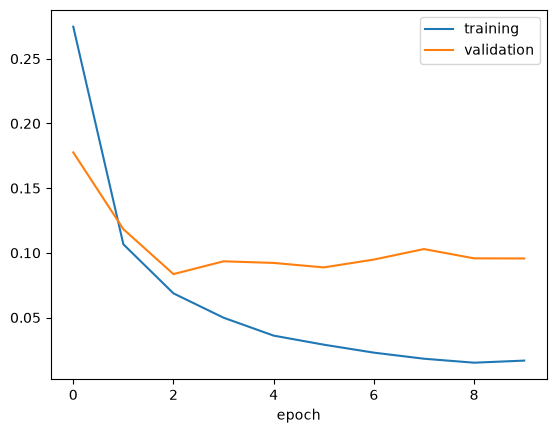

In [23]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="training")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"testitarkkuus {test_accuracy:.4f}")

testitarkkuus 0.9794


In [25]:
probabilities = model.predict(x_test[:3], verbose=0)
print(probabilities.round(3))
print("ennuste:", probabilities.argmax(axis=1), "oikein:", y_test[:3])

[[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]
ennuste: [7 2 1] oikein: [7 2 1]


In [26]:
model.save("mnist_fcn.keras")
model = keras.models.load_model("mnist_fcn.keras")

In [27]:
import tensorflow as tf 
print("TensorFlow version:", tf.__version__) 
print("Physical devices:",tf.config.list_physical_devices()) 
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.22.0-rc0
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU devices: []


In [28]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("MPS (Apple GPU) available:", torch.backends.mps.is_available())
print("MPS built:", torch.backends.mps.is_built())

PyTorch version: 2.14.1
CUDA available: False
MPS (Apple GPU) available: True
MPS built: True


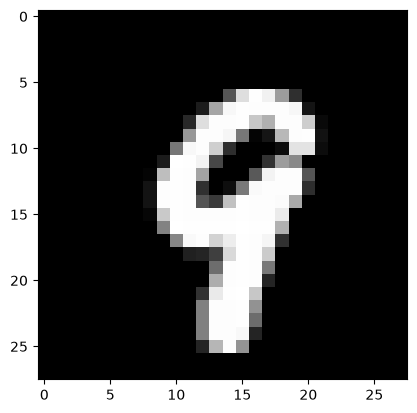

In [29]:
img = x_train[6969].reshape(28, 28)
plt.imshow(img, cmap="gray")
plt.show()